# Project 01: one protein against many ligands (all-inclusive)

## Generating a Shared Interaction Profile for Mpro Structures

The purpose is to find interaction hotspots in a single target through the analysis of interactions found in a dataset of diverse small compounds.

This pipeline was used to elucidate hotspots in the sars-cov-19 protease (**Mpro**), using the structures available from [Fragalysis](https://fragalysis.diamond.ac.uk/).

**This is the all-inclusive variant of `fragalysis.ipynb`.** Every interaction of every structure is counted:

* no rudimentary length/gap filters,
* no consensus threshold (`min_consensus=0.0`): every aligned position is kept,
* no masking (`mask_mismatches=False`): a structure counts at a position even if its amino acid there differs from the others.

So a row such as **S144** counts every residue aligned to Mpro position 144, whatever it is. The interactive tables show, per row, which amino acids those counts come from and how many of the structures carrying each amino acid actually interact.

The workflow itself consists of three steps:

1. Obtaining and sanitizing the data
2. Ingesting it in `plipify`
3. Generating publication-worthy figures

In [1]:
from pathlib import Path
from io import BytesIO
from zipfile import ZipFile
from subprocess import call, STDOUT
from urllib.request import urlopen

import requests
from tqdm.auto import tqdm
from matplotlib import cm, colors
from IPython.display import Image
import pandas as pd
from rdkit.Chem.PandasTools import AddMoleculeColumnToFrame
from Bio.PDB import PDBParser, PDBIO
import nglview as nv

from plipify.fingerprints import InteractionFingerprint
from plipify.visualization import (
    fingerprint_barplot, fingerprint_heatmap, fingerprint_table, 
    fingerprint_nglview, PymolVisualizer, nglview_color_side_chains_by_frequency,
    fingerprint_writepdb
)
from plipify.core import Structure

## Obtaining and sanitizing the data

### Select target of interest
Query Fragalysis for all downloadable targets.

In [2]:
# r = requests.get(f"https://fragalysis.diamond.ac.uk/api/targets/?format=json")
# r.raise_for_status()
# targets = [t["title"] for t in r.json()["results"] if t["zip_archive"]]
# print("Downloadable targets:", *targets)
!get_ipython().execution_count = 0

/bin/bash: -c: line 1: syntax error near unexpected token `.execution_count'
/bin/bash: -c: line 1: `get_ipython().execution_count = 0'


In [3]:
TARGET = "Mpro"  # other options, see above
target = "MPro" #placeholder to get legacy code to run

HERE = Path(_dh[-1])
DATA = HERE / "data" / TARGET
OUT = HERE / "output" / f"{TARGET}-all-inclusive"  # separate from fragalysis.ipynb
DATA.mkdir(exist_ok=True, parents=True)
OUT.mkdir(exist_ok=True, parents=True)

### Get data from fragalysis

We will be using data from [_Fragalysis_](https://fragalysis.diamond.ac.uk/), a XRC platform that generates structures for ligand collections against a given target. API endpoint is described [here](https://fragalysis.diamond.ac.uk/api/?format=api), but in short, you can download a full featured zip file using this URL: `https://fragalysis.diamond.ac.uk/media/targets/$TARGETNAME.zip`.

In [4]:
# r = requests.get(f"https://fragalysis.diamond.ac.uk/api/targets/?format=json&title={TARGET}")
# r.raise_for_status()
# target = r.json()["results"][0]

# if target["zip_archive"] is None:
#     raise ValueError(f"Target {TARGET} is not downloadable")

In [5]:
# metadata = requests.get(target["metadata"], stream=True)
# metadata = pd.read_csv(metadata.raw, index_col=0)
# AddMoleculeColumnToFrame(metadata, smilesCol="smiles")
# metadata

Prealigned PDBs for each row can be found in `data/{target}/aligned/{crystal_name}/{crystal_name}_bound.pdb`:

In [6]:
# If already downloaded, they should be here:
pdbs = list((DATA / "aligned").glob("**/*_bound.pdb"))

if not pdbs:
    if target["title"] != "Mpro":
        download_url = target["zip_archive"]
        response = requests.get(download_url, stream=True)
        response.raise_for_status()
        with BytesIO(response.raw.data) as b, ZipFile(b) as z:
            z.extractall(DATA)
    
    # NOTE: As of 2021.10.13, MPro dataset URL gives a 502 gateway error
    # The webapp uses https://zenodo.org/record/5226381 instead for MPro
    # We will use this one for now if that's the case
    else:
        # NOTE: The file is very large and will take a while to download!
        # Also we will need to download it in chunks.
        
        # Check if it has been downlaoded already (you can also copy it there manually)
        target_zip_file = Path('Mpro.zip')
        if not target_zip_file.is_file():
            print(f'Downloading zip file {target_zip_file} ... please wait.')
            zipurl='https://zenodo.org/record/5226381/files/Mpro.zip'
            with open('Mpro.zip', 'wb') as f:
                with urlopen(zipurl) as zipresp:
                    while True:
                        chunk = zipresp.read(1024)
                        if not chunk: break
                        f.write(chunk)
        # Check if zip file has been unzipped already
        if not (DATA / "aligned").exists():
            print(f'Unzipping file {target_zip_file} ... please wait.')
            # Unzip file
            with ZipFile(target_zip_file, 'r') as zip_ref:
                zip_ref.extractall(DATA / '..')        
    
    # Reassign now
    pdbs = list((DATA / "aligned").glob("**/*_bound.pdb"))
    assert pdbs, "Couldn't find downloaded PDB structures!"
    
print(f"# structures: {len(pdbs)}")

# structures: 587


The archive for MPro keeps changing contents (more structures being added), so we will filter the structures with the contents retrieved on 2022.01.24 for the sake of reproducibility.

In [7]:
if TARGET == "Mpro":
    all_pdbs = pdbs.copy()
    with open(HERE / "20220124_Mprodata.txt") as f:
        contents = set()
        for line in f:
            line = line.strip()
            if line.endswith(".pdb"):
                contents.add(line)
    pdbs = [pdb for pdb in all_pdbs 
            if str(Path(pdb).relative_to(HERE)) in contents]
    print("Filtered structures down to", len(pdbs), "files")

Filtered structures down to 587 files


As the directory name suggests, these are prealigned:contents

In [8]:
view = nv.NGLWidget()
for pdb in pdbs[:10]:
    structure = nv.adaptor.FileStructure(str(pdb))
    comp = view.add_component(structure, default_representation=False)
    comp.add_cartoon()
    comp.add_ball_and_stick("LIG")
view.center("LIG")
view

NGLWidget()

In [9]:
view.render_image(factor=1, trim=True, transparent=True, antialias=True);

In [10]:
view._display_image()

Notice how binding sites are not always the same.

### Prepare data

#### Split files by chain
To get one binding site per protein only

In [11]:
# If already split, they should be here:
pdbs_by_chain = list((DATA / "aligned").glob("**/*_bound_chain*[!wH].pdb"))

not_processed = []
    
if not pdbs_by_chain:
    for path in tqdm(pdbs):
        chain_id = path.stem.split('_')[1][-1]
        new_filename = path.parent / f"{path.stem}_chain{chain_id}{path.suffix}"

        ## Read the PDB file and extract the chain from structure[0]
        model = PDBParser(PERMISSIVE=1,QUIET=1).get_structure(path.stem, path)[0]
        ### Save new file
        if chain_id in model:
            io = PDBIO()
            io.set_structure(model[chain_id])
            io.save(str(new_filename))
        else:
            not_processed.append(path)
    
    # Reassign now
    pdbs_by_chain = list((DATA / "aligned").glob("**/*_bound_chain*[!wH].pdb"))

print(f"# structures: {len(pdbs_by_chain)}")
if(len(not_processed)>0):
    print(f"Could not process {len(not_processed)} structures:")
    print(" -", "\n - ".join(map(str, not_processed)))

# structures: 587


#### Protonate
Some ligands/residues are potentially incorrectly protonated with PLIP built-in fixers (OpenBabel). In this example, we take care of that using Amber's `reduce`.

In [12]:
def reduce(path):
    path = Path(path)
    output = path.parent / f"{path.stem}_wH{path.suffix}"
    with open(output, "wb") as f:
        # TODO-delete (recode): the return code of reduce is ignored, and stderr=STDOUT writes reduce's
        # log messages into the output PDB. Send stderr elsewhere and check the return code.
        call(["reduce", path], stdout=f, stderr=STDOUT)
    return output

In [13]:
# If already Hs added, they should be here:
pdbs_by_chain_wH = list((DATA / "aligned").glob("**/*_bound_chain*_wH.pdb"))

if not pdbs_by_chain_wH:
    pdbs_by_chain_wH = [reduce(pdb) for pdb in tqdm(pdbs_by_chain)]

print(f"# structures: {len(pdbs_by_chain_wH)}")
print(" -", "\n - ".join(map(str, pdbs_by_chain_wH[0:3])))

# structures: 587
 - /home/ben/Desktop/plipify/projects/01/data/Mpro/aligned/Mpro-P0776_0A/Mpro-P0776_0A_bound_chainA_wH.pdb
 - /home/ben/Desktop/plipify/projects/01/data/Mpro/aligned/Mpro-P1858_0A/Mpro-P1858_0A_bound_chainA_wH.pdb
 - /home/ben/Desktop/plipify/projects/01/data/Mpro/aligned/Mpro-z4ylu_0C/Mpro-z4ylu_0C_bound_chainC_wH.pdb


Check structures

In [14]:
view = nv.NGLWidget()
for pdb in pdbs_by_chain_wH[:10]:
    structure = nv.adaptor.FileStructure(str(pdb))
    comp = view.add_component(structure, default_representation=False)
    comp.add_cartoon()
    comp.add_ball_and_stick("LIG")
view.center("LIG")
view

NGLWidget()

## Ingesting it in `plipify` 

* `plipify` will be used for interaction hotspot analysis across a set of ligands co-crystalliezed to the same protein.
* It is built on top of Protein–Ligand Interaction Profiler, or [PLIP](https://plip-tool.biotec.tu-dresden.de/plip-web/plip/index), used to get insight into protein-ligand interactions. 

### Build structure and binding site from pdb
For this exercise, we will only keep structures that contain exactly one binding site.

In [15]:
structures = []
for path in tqdm(pdbs_by_chain_wH):
    # TODO-delete (recode): files were already protonated with reduce, but protonate defaults to True,
    # so PLIP protonates again. Decide whether to pass protonate=False.
    structure = Structure.from_pdbfile(str(path), ligand_name="LIG")
    if len(structure.binding_sites) != 1:
        print(f"{path.relative_to(HERE)} contains {len(structure.binding_sites)} binding sites and we want exactly one.")
        continue
    structures.append(structure)

  0%|          | 0/587 [00:00<?, ?it/s]

data/Mpro/aligned/Mpro-z4ylu_0C/Mpro-z4ylu_0C_bound_chainC_wH.pdb contains 0 binding sites and we want exactly one.
data/Mpro/aligned/Mpro-z4ylu_0D/Mpro-z4ylu_0D_bound_chainD_wH.pdb contains 0 binding sites and we want exactly one.
data/Mpro/aligned/Mpro-z7kvl_0A/Mpro-z7kvl_0A_bound_chainA_wH.pdb contains 0 binding sites and we want exactly one.
data/Mpro/aligned/Mpro-z7kvr_0B/Mpro-z7kvr_0B_bound_chainB_wH.pdb contains 0 binding sites and we want exactly one.
data/Mpro/aligned/Mpro-z2zu2_0A/Mpro-z2zu2_0A_bound_chainA_wH.pdb contains 0 binding sites and we want exactly one.
data/Mpro/aligned/Mpro-x1101_1A/Mpro-x1101_1A_bound_chainA_wH.pdb contains 2 binding sites and we want exactly one.
data/Mpro/aligned/Mpro-z7l14_0A/Mpro-z7l14_0A_bound_chainA_wH.pdb contains 0 binding sites and we want exactly one.
data/Mpro/aligned/Mpro-z7l13_0A/Mpro-z7l13_0A_bound_chainA_wH.pdb contains 0 binding sites and we want exactly one.
data/Mpro/aligned/Mpro-z2zu2_1A/Mpro-z2zu2_1A_bound_chainA_wH.pdb contai

Count type of structures

In [16]:
n_structures_by_type = {'Mpro-P': 0, 'Mpro-x': 0, 'Mpro-z': 0, 'other': 0}
for s in structures:
    name_code = s.identifier[0:6]
    if name_code in n_structures_by_type:
        n_structures_by_type[name_code] += 1
    else:
        n_structures_by_type['other'] += 1
print(n_structures_by_type)

{'Mpro-P': 186, 'Mpro-x': 360, 'Mpro-z': 12, 'other': 0}


### Generate the all-inclusive interaction fingerprint

#### Align all structures

MUSCLE lines up the sequences so that equivalent residues sit in the same column (alignment position),
even when structures have different lengths, unresolved residues or come from a related virus.
With `min_consensus=0.0` and `mask_mismatches=False`, every column is kept and every structure keeps its own
residue in every column, so nothing is dropped or masked.

MUSCLE takes several minutes for ~550 structures. The result is cached in `OUTPUT`, so a rerun with the same
structures is instant.

In [17]:
import hashlib
import json
from collections import Counter

import numpy as np
from IPython.display import HTML, Markdown, display
from matplotlib import colormaps
from matplotlib.colors import Normalize, to_hex
from Bio.SeqUtils import seq1

# cache key: the identifiers and sequences of the structures, in order
cache_key = hashlib.sha1("\n".join(f"{s.identifier}\t{s.sequence()}" for s in structures).encode()).hexdigest()[:12]
mapping_file = OUT / f"all_inclusive_mapping_{cache_key}.json"

if mapping_file.exists():
    mapping = [{int(col): kwargs for col, kwargs in m.items()} for m in json.loads(mapping_file.read_text())]
    print(f"Using cached alignment mapping {mapping_file.relative_to(HERE)}")
else:
    mapping = InteractionFingerprint.calculate_indices_mapping(structures, min_consensus=0.0, mask_mismatches=False)
    mapping_file.write_text(json.dumps(mapping))

print(f"{len(structures)} structures, {len(mapping[0])} aligned positions")

Using cached alignment mapping output/Mpro-all-inclusive/all_inclusive_mapping_da22a94b07fc.json
558 structures, 308 aligned positions


#### Interactions of every structure at every position

`calculate_fingerprint(..., cumulative=False)` returns one fingerprint per structure, each bit labelled with that
structure's own residue. This is turned into a table with one row per structure and aligned position where the
structure has a residue.

In [18]:
interaction_types = list(InteractionFingerprint().interaction_types)
columns = list(mapping[0])   # aligned positions, in fingerprint order

per_structure = InteractionFingerprint().calculate_fingerprint(
    structures, residue_indices=mapping, labeled=True, cumulative=False
)
if len(per_structure) != len(structures):
    raise RuntimeError("Some structures could not be fingerprinted (see the warnings above)")

records = []
for structure, bits in zip(structures, per_structure):
    for i, column in enumerate(columns):
        residue_bits = bits[i * len(interaction_types):(i + 1) * len(interaction_types)]
        residue = residue_bits[0].label["residue"]
        if residue.name == "GAP":   # no residue resolved at this position
            continue
        records.append({
            "structure": structure.identifier.split("_bound")[0],
            "column": column,
            "residue": residue.name.title(),   # e.g. "Ser"
            "seq_index": residue.seq_index,
            **{b.label["type"]: b.value for b in residue_bits},
        })

per_residue = pd.DataFrame(records)
per_residue["total"] = per_residue[interaction_types].sum(axis=1)
print(f"{len(per_residue)} residues in {per_residue.structure.nunique()} structures, "
      f"{int(per_residue.total.sum())} interactions in total")
per_residue[per_residue.total > 0].head()

169241 residues in 558 structures, 2723 interactions in total


,structure,column,residue,seq_index,hydrophobic,hbond-don,hbond-acc,waterbridge,saltbridge,pistacking,pication,halogen,metal,covalent,total
40,Mpro-P0776_0A,41,His,41,0,0,0,0,0,1,0,0,0,0,1
141,Mpro-P0776_0A,142,Asn,142,1,0,1,0,0,0,0,0,0,0,2
164,Mpro-P0776_0A,166,Met,165,1,0,0,0,0,0,0,0,0,0,1
165,Mpro-P0776_0A,167,Glu,166,1,1,0,0,0,0,0,0,0,0,2
342,Mpro-P1858_0A,41,His,41,0,0,0,0,0,1,0,0,0,0,1


#### Name each aligned position

Each position is named after its most common amino acid and its most common residue number, e.g. `S144`.
Almost all structures use the same Mpro numbering, so this is the familiar residue number (not the alignment column,
which is shifted wherever any structure has an extra residue).

A position that only a few structures have (an insertion in a related protein) can end up with the same number as a
real Mpro position. Such a position is marked as an insertion (`ins` in its name). It is shown in the tables but left
out of the 3D figures, because it has no counterpart residue in the structure that is drawn.

In [19]:
def one_letter(name):
    letter = seq1(name)
    return letter if letter != "X" else f"[{name}]"

sites = per_residue.groupby("column").agg(
    residue=("residue", lambda s: s.mode()[0]),
    number=("seq_index", lambda s: s.mode()[0]),
    structures=("structure", "size"),
)
# for positions sharing a number, the one present in the most structures keeps it; the others are insertions
sites["insertion"] = sites.sort_values("structures", ascending=False).duplicated("number")
sites["label"] = [f"{one_letter(r.residue)}{r.number}" + (f" ins (col {col})" if r.insertion else "")
                  for col, r in sites.iterrows()]
print(f"{len(sites)} positions, {int(sites.insertion.sum())} insertions")
sites[sites.insertion]

308 positions, 3 insertions


,residue,number,structures,insertion,label
column,,,,,
156,Gly,155,2,True,G155 ins (col 156)
305,Asn,301,1,True,N301 ins (col 305)
307,Phe,305,14,True,F305 ins (col 307)


#### Cumulative fingerprint

The same table as in `fragalysis.ipynb`: interactions per position (rows) and interaction type (columns), summed
over all structures. Positions without interactions and interaction types that never occur are removed.

`fp` is indexed by residue number so that the plots and 3D figures below colour the right residues;
`fp_labeled` is the same table with the position names, including insertions.

In [20]:
fp_labeled = per_residue.groupby("column")[interaction_types].sum()
fp_labeled = fp_labeled.loc[(fp_labeled != 0).any(axis=1), (fp_labeled != 0).any(axis=0)]
interacting_insertions = sites.loc[fp_labeled.index][lambda s: s.insertion]

fp = fp_labeled.drop(index=interacting_insertions.index)
fp.index = sites.loc[fp.index, "number"].astype(int)
fp.index.name = "residue"
fp_labeled.index = sites.loc[fp_labeled.index, "label"]
fp_labeled.index.name = "position"

if not fp.values.shape[0]:
    raise ValueError("Fingerprint is empty!")
print(f"{len(fp_labeled)} interacting positions, {int(fp_labeled.values.sum())} interactions")
if len(interacting_insertions):
    print("Interacting insertions (in the tables, not in the 3D figures):", ", ".join(interacting_insertions.label))

66 interacting positions, 2723 interactions


#### Which amino acids add up to each count

For every position and every amino acid found there:

* **structures**: how many structures have this amino acid at this position,
* **interacting**: how many of those make at least one interaction here, and what share that is,
* **interactions**: how many interactions they make (per type and in total); summed over the amino acids of a
  position, this is the position's total in the fingerprint.

The table printed here only lists the positions where **more than one amino acid interacts**. The interactive
tables below show the numbers for every position when you hover over a row, and the full table is saved as CSV.

In [21]:
breakdown = per_residue.groupby(["column", "residue"]).agg(
    structures=("structure", "size"),
    interacting=("total", lambda t: int((t > 0).sum())),
    **{t: (t, "sum") for t in interaction_types},
    interactions=("total", "sum"),
).reset_index()
breakdown["interacting %"] = (100 * breakdown.interacting / breakdown.structures).round(1)
breakdown.insert(0, "position", sites.loc[breakdown.column, "label"].to_numpy())
breakdown = breakdown.sort_values(["column", "interactions", "structures"], ascending=[True, False, False])
breakdown.drop(columns="column").to_csv(OUT / "all_inclusive_breakdown.csv", index=False)

# positions where more than one amino acid contributes interactions
shown_types = list(fp_labeled.columns)
mixed = breakdown[breakdown.interactions > 0].groupby("position", sort=False).filter(lambda g: len(g) > 1)
print(f"Positions where more than one amino acid interacts: {mixed.position.nunique()} "
      f"(all positions and amino acids are in {(OUT / 'all_inclusive_breakdown.csv').name})")
mixed[["position", "residue", "structures", "interacting", "interacting %", *shown_types, "interactions"]]

Positions where more than one amino acid interacts: 6 (all positions and amino acids are in all_inclusive_breakdown.csv)


,position,residue,structures,interacting,interacting %,hydrophobic,hbond-don,hbond-acc,waterbridge,saltbridge,pistacking,pication,halogen,interactions
69,H41,His,556,373,67.1,37,6,13,0,1,336,16,0,409
68,H41,Ala,2,1,50.0,1,0,0,0,0,0,0,0,1
294,C145,Cys,557,79,14.2,0,79,0,0,0,0,0,0,79
295,C145,Ser,1,1,100.0,0,2,0,0,0,0,0,0,2
335,M165,Met,549,269,49.0,269,0,0,0,0,0,0,0,269
334,M165,Leu,7,7,100.0,8,0,0,0,0,0,0,0,8
333,M165,Ile,2,2,100.0,2,0,0,0,0,0,0,0,2
339,P168,Pro,549,4,0.7,4,0,0,0,0,0,0,0,4
338,P168,Gly,2,1,50.0,0,0,0,1,0,0,0,0,1
382,T190,Thr,549,7,1.3,1,1,5,0,0,0,0,0,7


### Interactive table

Same colours as the usual table (`YlGnBu`, darker = more interactions). **Hover over a row** to see which amino
acids sit at that position, how many structures carry each one, how many of those interact, and how many
interactions of each type they contribute.

In [ ]:
def interactive_table(table):
    """
    HTML version of `table` (positions x interaction types) with a hover panel per row.
    If there are some structures unresolved, there were some crystal structures that we not available in their X-ray data.
    """
    uid = f"ai{abs(hash((tuple(table.index), tuple(table.columns)))) % 10**8}"
    cmap = colormaps["YlGnBu"]
    norm = Normalize(vmin=0, vmax=max(table.values.max(), 1))
    n_structures = len(structures)
    label_to_column = dict(zip(sites.label, sites.index))
    by_column = {col: g for col, g in breakdown.groupby("column")}

    def cell(value):
        rgba = cmap(norm(value))
        light = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2] > 0.55
        return f'<td style="background:{to_hex(rgba)};color:{"#111" if light else "#fff"}">{int(value)}</td>'

    def panel(label):
        g = by_column[label_to_column[label]]
        present = int(g.structures.sum())
        head = "".join(f"<th>{t}</th>" for t in table.columns)
        rows = "".join(
            f"<tr><td class='res'>{r['residue']}</td><td>{r['structures']}</td>"
            f"<td>{r['interacting']} ({r['interacting %']:g}%)</td>"
            + "".join(f"<td>{int(r[t])}</td>" for t in table.columns)
            + f"<td><b>{int(r['interactions'])}</b></td></tr>"
            for _, r in g.iterrows()
        )
        total = "".join(f"<td>{int(table.at[label, t])}</td>" for t in table.columns)
        return (f"<div class='tip'><div class='tiphead'><b>{label}</b>: residue present in {present} of "
                f"{n_structures} structures ({n_structures - present} unresolved)</div>"
                f"<table><tr><th>amino acid</th><th>structures</th><th>interacting</th>{head}<th>total</th></tr>"
                f"{rows}<tr class='sum'><td>all</td><td>{present}</td><td></td>{total}"
                f"<td><b>{int(table.loc[label].sum())}</b></td></tr></table></div>")

    half = len(table) // 2
    body = "".join(
        f"<tr class='{'up' if i >= half and len(table) > 6 else ''}'><td class='site'>{label}{panel(label)}</td>"
        + "".join(cell(v) for v in table.loc[label]) + "</tr>"
        for i, label in enumerate(table.index)
    )
    head = "".join(f"<th>{t}</th>" for t in table.columns)
    style = f"""<style>
    .{uid} {{font-size:12px}}
    .{uid} > table {{border-collapse:collapse}}
    .{uid} > table > tbody > tr > th, .{uid} > table > tbody > tr > td {{padding:3px 9px;text-align:right;border:1px solid #fff}}
    .{uid} td.site {{position:relative;text-align:left;font-weight:600;white-space:nowrap;cursor:help;background:#f3f3f3;color:#111}}
    .{uid} > table > tbody > tr:hover > td {{outline:2px solid #222;outline-offset:-2px}}
    .{uid} .tip {{display:none;position:absolute;left:100%;top:0;z-index:1000;background:#fff;color:#111;
        border:1px solid #999;box-shadow:0 3px 10px rgba(0,0,0,.25);padding:8px 10px;font-weight:400;white-space:nowrap}}
    .{uid} tr.up .tip {{top:auto;bottom:0}}
    .{uid} tr:hover .tip {{display:block}}
    .{uid} .tip table {{border-collapse:collapse;margin-top:6px}}
    .{uid} .tip th, .{uid} .tip td {{padding:2px 8px;text-align:right;border-bottom:1px solid #e3e3e3}}
    .{uid} .tip td.res {{text-align:left;font-weight:600}}
    .{uid} .tip tr.sum td {{border-top:2px solid #999;border-bottom:none}}
    </style>"""
    return HTML(f"{style}<div class='{uid}'><table><tr><th style='text-align:left'>position</th>{head}</tr>"
                f"{body}</table></div>")


interactive_table(fp_labeled)

This fingerprint is too sparse, let's try to focus on the hotspots only (arbitrarily defined now as "residue with more than 5 total interactions, regardless the type")

In [23]:
fp_focused = fp[fp.sum(axis=1) > 5]
fp_labeled_focused = fp_labeled[fp_labeled.sum(axis=1) > 5]

In [24]:
interactive_table(fp_labeled_focused)

## Analyze and visualize the results

* First, we will look at the different representations for the interation hot spots.
* Then, we will visualize the interactions in 3D
    * nglview
    * pymol

### Interaction visualizations: Barplot, heatmap and table

`plipify` provides several views for the aggregated interaction fingerprints.

#### Barplot

In [25]:
fingerprint_barplot(fp_focused)

#### Heatmap

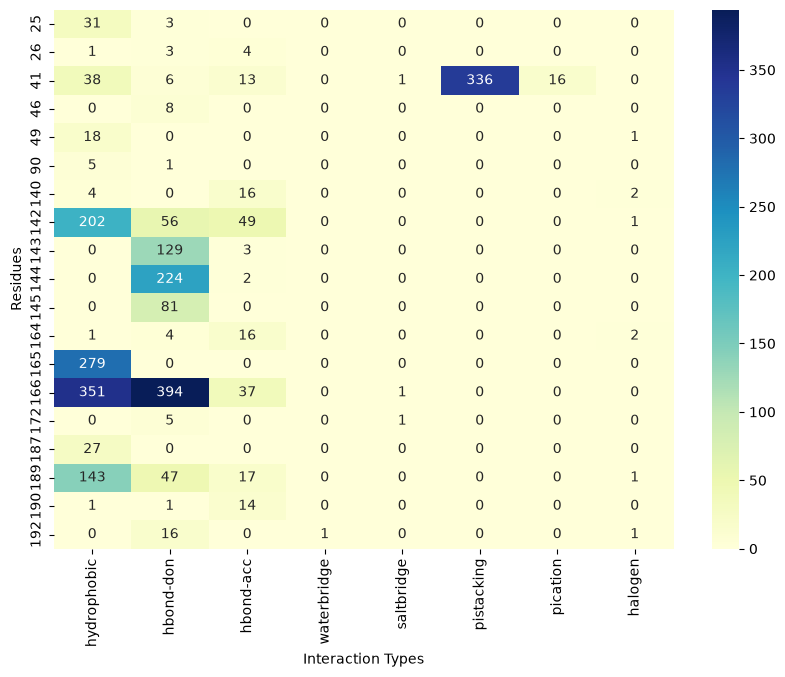

In [26]:
fingerprint_heatmap(fp_focused, cmap="YlGnBu");

#### Table
One-letter residue names are taken from a SARS-CoV-2 structure (`Mpro-P1788_0A`); the rows are already residue numbers.

In [27]:
table_structure = next(s for s in structures if s.identifier.startswith("Mpro-P1788_0A"))
fingerprint_table(fingerprint_df=fp_focused, structure=table_structure)

HTML(value='\n    <style>\n    \n\n    table.plipify-legend {\n        text-align: center;\n        color: #ff…

### 3D Visualization

#### Pick a structure for drawing purposes
* We pick the lead compound methoxy for visualization purposes
* Contained in the structure **Mpro-P1788_0A**

In [28]:
selected_name = "Mpro-P1788"
# TODO-delete (recode): next(...) takes the first name match, which may be _0B rather than the _0A
# the text above says. Match the full name, e.g. "Mpro-P1788_0A".
selected_structure = next(s for s in structures if selected_name in s.identifier)
selected_pdb = next(p for p in pdbs_by_chain_wH if selected_name in str(p))

#### Visualizations using nglview

Color side chains by frequency of interactions they contribute to.

In [29]:
view = nglview_color_side_chains_by_frequency(fp_focused, selected_pdb)
view.center("LIG")
view

NGLWidget()

Show specific interactions for a protein-ligand complex.

In [30]:
view = fingerprint_nglview(fp_focused, selected_structure)
view.center("LIG")
view

NGLWidget()

In [31]:
view.render_image(factor=1, trim=True, transparent=True, antialias=True);

In [32]:
view._display_image()

Show information generated by PLIP for a specific complex.

In [33]:
# TODO-delete (recode): the trailing ';' hides the output, so this cell shows nothing.
# Remove the ';' or delete the cell.
selected_structure.to_dataframes();

### LIG:B:403

#### Hydrophobic

,RESNR,RESTYPE,RESCHAIN,RESNR_LIG,RESTYPE_LIG,RESCHAIN_LIG,DIST,LIGCARBONIDX,PROTCARBONIDX,LIGCOO,PROTCOO
0,165,MET,B,403,LIG,B,3.59,4695,2522,"(11.608, -0.999, 22.136)","(12.004, 1.132, 19.275)"
0,166,GLU,B,403,LIG,B,3.78,4707,2539,"(4.894, 1.402, 19.21)","(7.468, 4.038, 18.361)"


#### Hbond-Don

,RESNR,RESTYPE,RESCHAIN,RESNR_LIG,RESTYPE_LIG,RESCHAIN_LIG,SIDECHAIN,DIST_H-A,DIST_D-A,DON_ANGLE,PROTISDON,DONORIDX,DONORTYPE,ACCEPTORIDX,ACCEPTORTYPE,LIGCOO,PROTCOO
0,189,GLN,B,403,LIG,B,True,2.32,3.07,145.34,True,2876,Nam,4686,O2,"(8.748, 3.875, 25.141)","(10.101, 3.268, 27.825)"
0,166,GLU,B,403,LIG,B,False,2.14,2.96,158.67,True,2537,Nam,4699,O2,"(9.226, 1.272, 21.077)","(9.529, 2.691, 18.497)"


#### Pistacking

,RESNR,RESTYPE,RESCHAIN,RESNR_LIG,RESTYPE_LIG,RESCHAIN_LIG,PROT_IDX_LIST,CENTDIST,ANGLE,OFFSET,TYPE,LIG_IDX_LIST,LIGCOO,PROTCOO
0,41,HIS,B,403,LIG,B,"608,609,610,611,612",5.41,80.25,1.42,T,"4691,4692,4693,4694,4695,4696","(12.160666666666666, 0.026666666666666655, 22....","(11.970600000000001, -5.204, 21.538)"


#### Generating publication-worthy figures

We provide here a semi-automated pipeline, to generate high-resolution figures of the interaction frequencies mapped on the protein structure, using pymol.

Below is an example of 
1) Creating PDB files for each interaction type found by `InteractionFingerprint().calculate_fingerprint()` (Frequencies are stored in the b-factor columns). 
2) Producing images of these using the PyMol API.

Note: The current hard-coded view is based on the aligned MPro structures.

In [34]:
# TODO-delete: hardcoded relative path that overrides selected_pdb from the selection cell.
# Delete once that cell is fixed to pick the _0A structure.
selected_pdb="./data/Mpro/aligned/Mpro-P1788_0A/Mpro-P1788_0A_bound_chainA_wH.pdb" 

In [35]:
# Using the methoxy ligand as an example
print(f' Selected structure: {selected_pdb}')
# TODO-delete (recode): same protonate=True question as the structure-building cell.
methoxy = Structure.from_pdbfile(path=str(selected_pdb))

 Selected structure: ./data/Mpro/aligned/Mpro-P1788_0A/Mpro-P1788_0A_bound_chainA_wH.pdb


Write interaction hotspots to a PDB file

* Create individual PDB files based on the interaction type.
* This will produce PDB files with bfactor values per residue representing the number of ligand interactions at that particular site. 

We also set the `summed` flag to `True` to add up all interactions and generate a PDB file containing all interaction types summed together.

In [36]:
pdb_interactions = fingerprint_writepdb(fingerprint_df=fp, structure=methoxy, output_path=OUT, ligand=True, summed=True, verbose=False)

/home/ben/Desktop/plipify/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:885: UserWarning: Unit cell dimensions not found. CRYST1 record set to unitary values.
  warnings.warn(
/home/ben/Desktop/plipify/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'formalcharges' Using default value of '0'
  warnings.warn(
/home/ben/Desktop/plipify/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:885: UserWarning: Unit cell dimensions not found. CRYST1 record set to unitary values.
  warnings.warn(
/home/ben/Desktop/plipify/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'formalcharges' Using default value of '0'
  warnings.warn(


One structure object per interaction type is created, as well as one for the summed interactions over all types.

In [37]:
pdb_interactions['hydrophobic']

<Structure with 306 residues, 1 ligands (0 of which were ignored) and 1 characterized binding sites. (loaded from file `/home/ben/Desktop/plipify/projects/01/output/Mpro-all-inclusive/interaction_pdbs/sys_int_hydrophobic.pdb`)>

In [38]:
pdb_interactions['summed_interactions']

<Structure with 306 residues, 1 ligands (0 of which were ignored) and 1 characterized binding sites. (loaded from file `/home/ben/Desktop/plipify/projects/01/output/Mpro-all-inclusive/interaction_pdbs/sys_summed_interactions.pdb`)>

We will use the `VisPymol` class to make a figure of all interactions summed. 

This is the color palette:
 * 0: `hydrophobic` - forest
 * 1: `hbond-don` - deepblue
 * 2: `hbond-acc` - olive
 * 3: `saltbridge` - purple
 * 4: `pistacking` - brown 
 * 5: `pication` - lightpink
 * 6: `halogen` - gray
 * 7: `summed_interactions` - yellow

In [39]:
spectrum_colors = {
    "hydrophobic": "white_forest", 
    "hbond-don": "white_deepblue", 
    "hbond-acc": "white_olive", 
    "saltbridge": "white_purple", 
    "pistacking": "white_brown", 
    "pication": "white_lightpink", 
    "halogen": "white_gray", 
    "summed_interactions": "white_yellow",
    "waterbridge": "white_cyan"  # any PyMOL spectrum name that exists
}

# supply view from PyMol "get_view" command
mpro_view = "\
            -0.665904999,   -0.394821048,   -0.632996082,\
            0.296537369,   -0.918650806,    0.261042088,\
            -0.684570849,   -0.013875127,    0.728814185,\
            0.000000000,    0.000000000,  -95.144737244,\
            8.413966179,   -0.994599819,   22.830898285,\
            56.102233887,  134.187240601,   20.000000000 "

for interaction_name, interaction_structure in pdb_interactions.items():
    v = PymolVisualizer(pdb=interaction_structure._path, verbose=False)
    v.set_style()
    v.create_image(
        surface=True, ligand_col="cyan", spectrum_col=spectrum_colors[interaction_name], 
        view=mpro_view, viewport_x=900, viewport_y=900
    )
    v.render(name=f"{interaction_name}_pymol_image", save_path=str(OUT))

PyMOL>viewport 900,900
PyMOL>viewport 900,900
PyMOL>viewport 900,900
PyMOL>viewport 900,900
PyMOL>viewport 900,900
PyMOL>viewport 900,900
PyMOL>viewport 900,900
PyMOL>viewport 900,900
PyMOL>viewport 900,900


Show sample figure

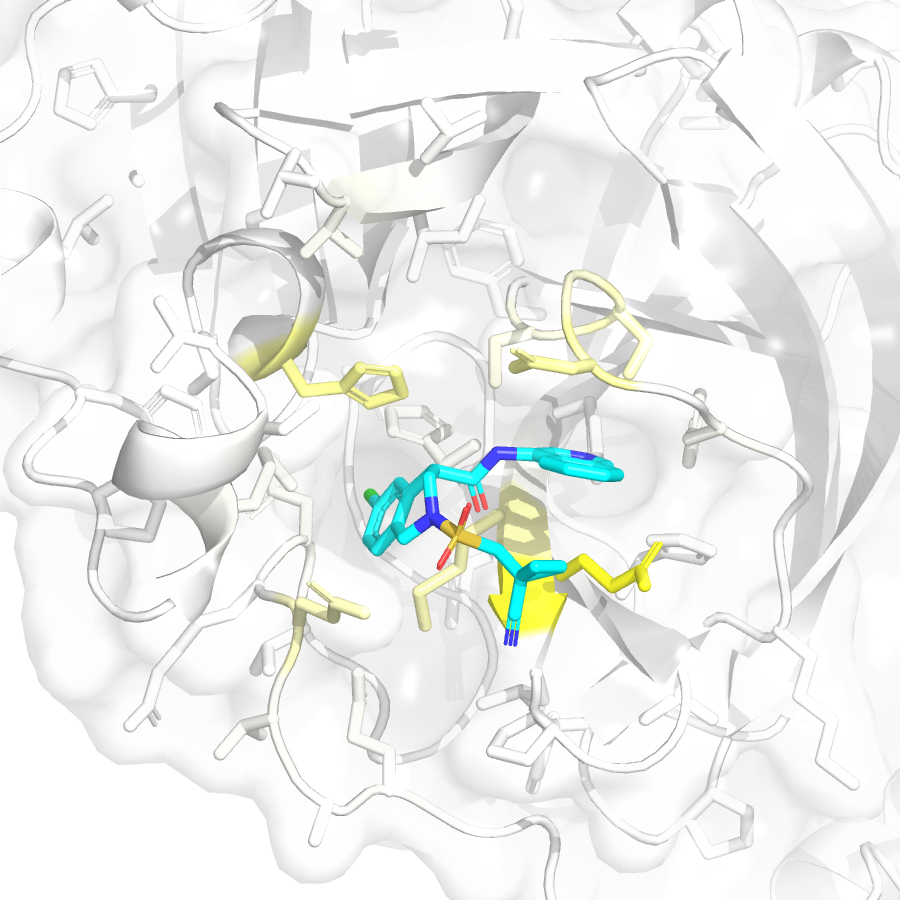

In [40]:
Image(filename=OUT / "summed_interactions_pymol_image.png", width=300, height=300)

We also may want to remove the ligand from the image, this can be done with the `show_ligand` flag: 

In [41]:
for interaction_name, interaction_structure in pdb_interactions.items():
    v = PymolVisualizer(pdb=interaction_structure._path, verbose=False)
    v.set_style()
    v.create_image(
        surface=True, ligand_col="cyan", spectrum_col=spectrum_colors[interaction_name],
        show_ligand=False, view=mpro_view, viewport_x=900, viewport_y=900)
    v.render(name=f"{interaction_name}_pymol_image_no_ligand", save_path=OUT)

PyMOL>viewport 900,900
PyMOL>viewport 900,900
PyMOL>viewport 900,900
PyMOL>viewport 900,900
PyMOL>viewport 900,900
PyMOL>viewport 900,900
PyMOL>viewport 900,900
PyMOL>viewport 900,900
PyMOL>viewport 900,900


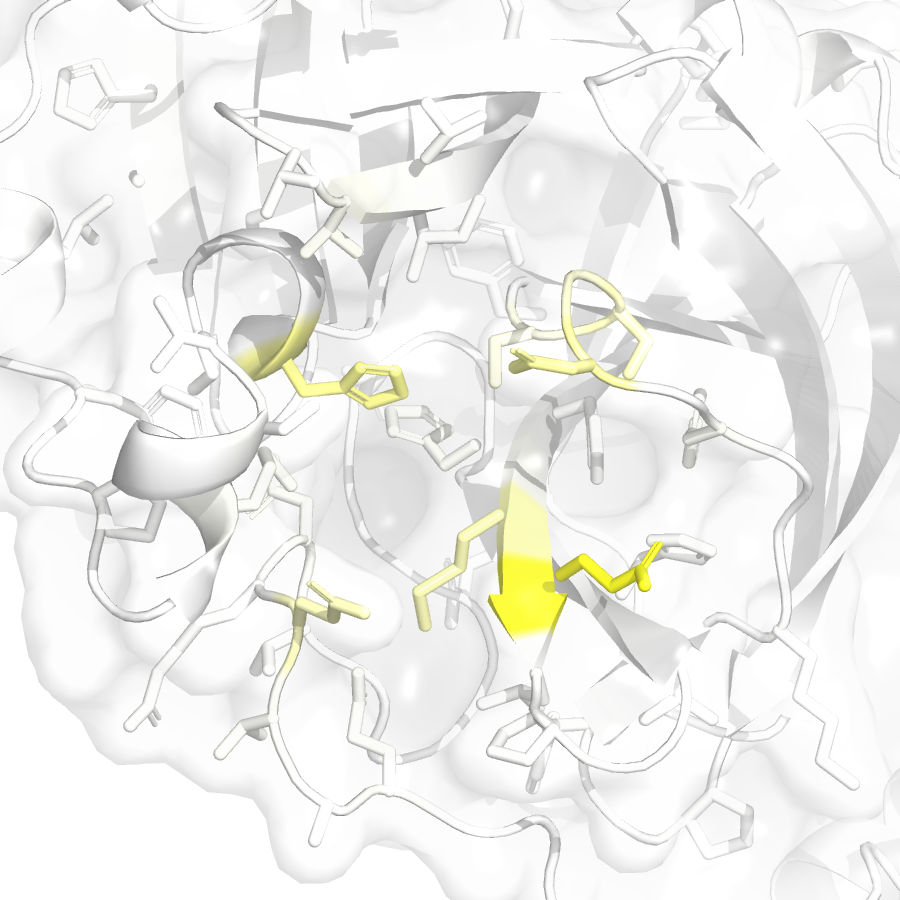

In [42]:
Image(filename=OUT / "summed_interactions_pymol_image_no_ligand.png", width=300, height=300) 

Sometimes when rendering residues as "sticks" they can appear to float above beta sheets. One way to get around this is to ensure beta sheets follow the backbone residues (at a cost of visual aesthetics) e.g.

In [43]:
for interaction_name, interaction_structure in pdb_interactions.items():
    v = PymolVisualizer(pdb=interaction_structure._path, verbose=False)
    v.set_style(flat_sheets=0)
    v.create_image(
        surface=True, ligand_col="cyan", spectrum_col=spectrum_colors[interaction_name],
        show_ligand=False, view=mpro_view, viewport_x=900, viewport_y=900)
    v.render(name=f"{interaction_name}_pymol_image_no_ligand_undulating_sheets", save_path=OUT)

PyMOL>viewport 900,900
PyMOL>viewport 900,900
PyMOL>viewport 900,900
PyMOL>viewport 900,900
PyMOL>viewport 900,900
PyMOL>viewport 900,900
PyMOL>viewport 900,900
PyMOL>viewport 900,900
PyMOL>viewport 900,900


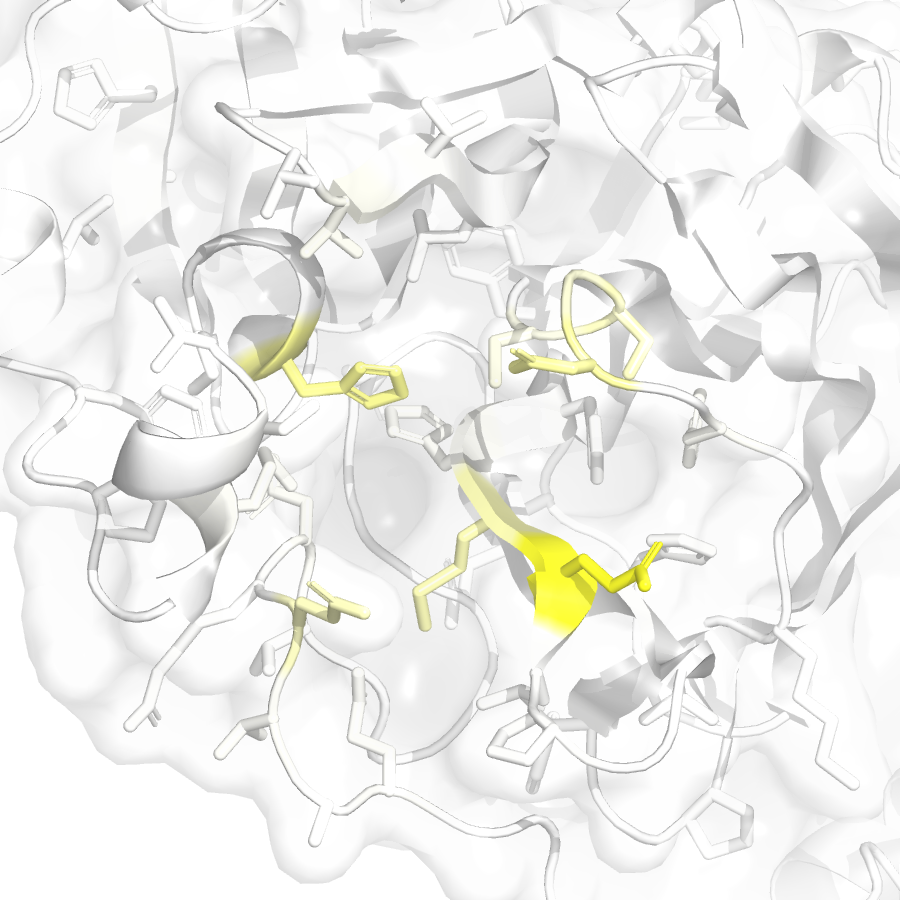

In [44]:
Image(filename=OUT / "summed_interactions_pymol_image_no_ligand_undulating_sheets.png", width=300, height=300)